In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

Exploring the file

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [8]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

<Axes: xlabel='category', ylabel='count'>

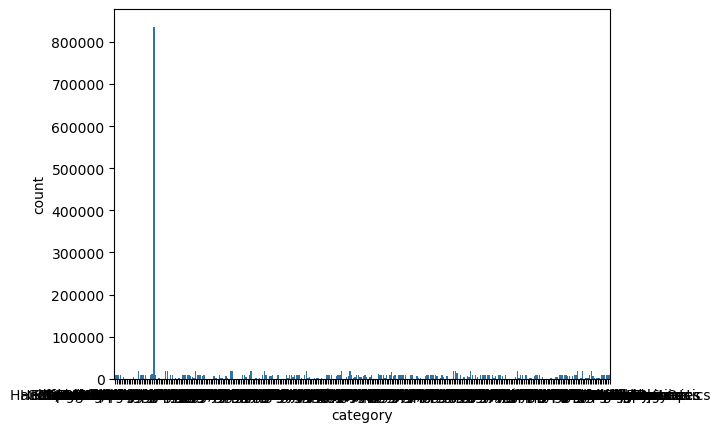

In [9]:
# Bar chart all categories.

sns.countplot(data= df, x = "category")



Bar Chart  TOP 10 categories for better view

In [10]:
top_ten = df["category"].value_counts().head(10)

top_ten

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

<Axes: xlabel='category'>

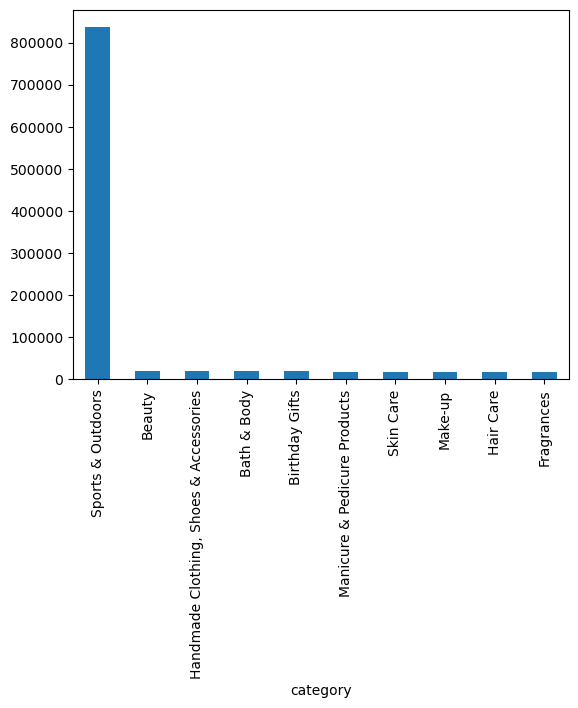

In [11]:
top_ten.plot.bar()

Top 5 Categories:

In [12]:
top_five = df["category"].value_counts().head(5)

top_five

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

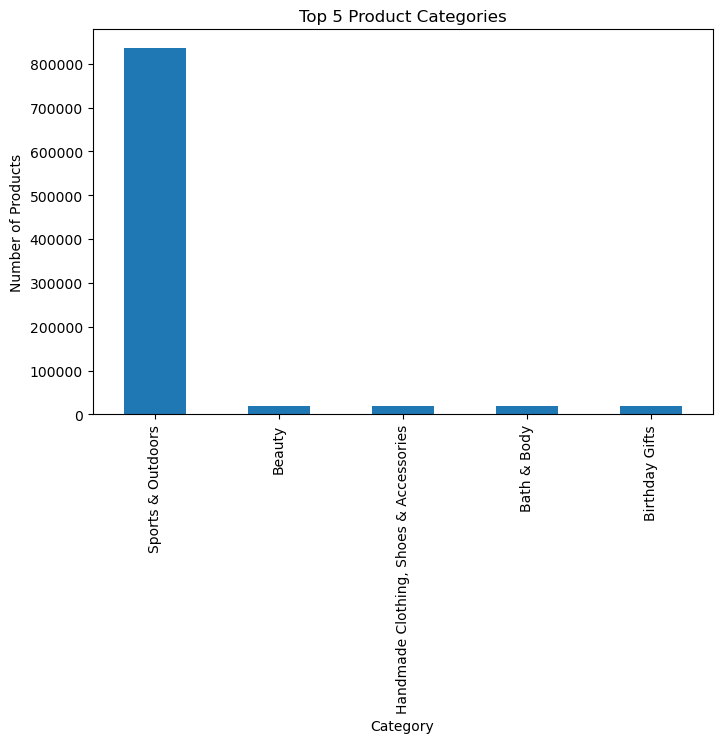

In [13]:

plt.figure(figsize=(8,5))

top_five.plot.bar()

plt.title("Top 5 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")

plt.show()

### Findings

Sports & Outdoors dominates the dataset, accounting for substantially more listings than any other category. In contrast, the remaining top four categories have relatively similar frequencies, with no clear dominance among them.

Pie Chart

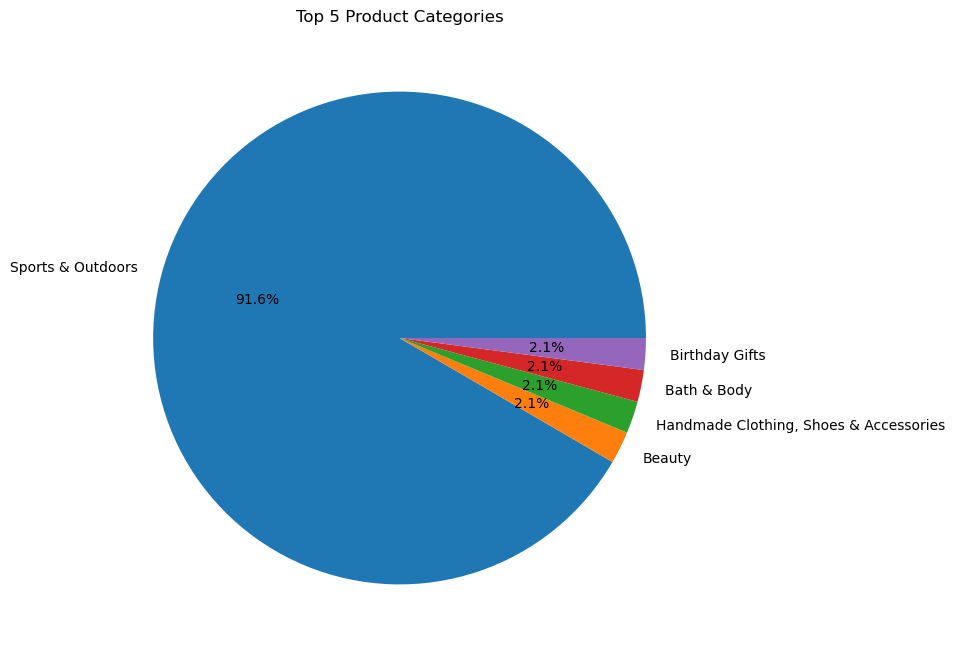

In [14]:
plt.figure(figsize=(8,8))

top_five.plot.pie(
    autopct="%1.1f%%"
)

plt.title("Top 5 Product Categories")
plt.ylabel("") 
plt.show()

Sports & Outdoors clearly dominates the product listings, representing the vast majority of the top five categories. The remaining categories account for only a small proportion of the listings.

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

### Statistics of Price of products

In [15]:
df["price"].mean() #to find the mean

np.float64(89.24380943923661)

In [16]:
df["price"].mean().round(2) #making shorter the number for better presentation.

np.float64(89.24)

In [17]:
df["price"].median() #to find the middle of the prices

19.09

In [18]:
df["price"].mode() #to find the most frequent

0    9.99
Name: price, dtype: float64

The average price it's 89.24 pounds.

In [19]:
df["price"].var() #to find the dispersion

119445.48532256528

In [20]:
df["price"].std() #to find how they are spreaded

345.60886175352226

In [21]:
df["price"].max() - df["price"].min() #to find the range.

100000.0

The product prices show a high level of variability. The standard deviation is 345.61, indicating that prices are widely spread around the mean. In addition, the range is 100,000, which suggests a very large difference between the cheapest and the most expensive products. These measures indicate a significant spread in product prices and suggest the presence of very expensive products (potential outliers).

## Visualization of Statistics

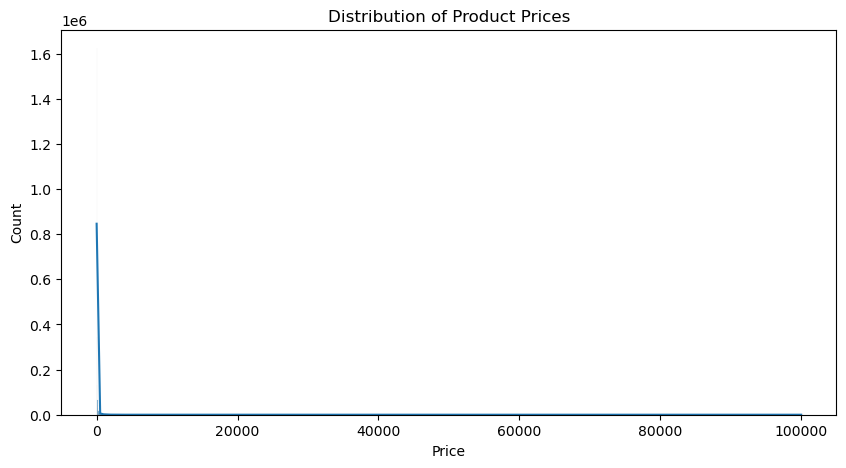

In [22]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x="price", kde=True)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()

Observation: The histogram is difficult to interpret because a small number of very expensive products stretch the x-axis. As a result, most products are concentrated near the lower price range, making the distribution hard to visualize. This could be improved by limiting the x-axis, removing extreme outliers for visualization purposes, or using a logarithmic scale.

The visualization can be improved by limiting the x-axis to focus on the price range where most products are concentrated.

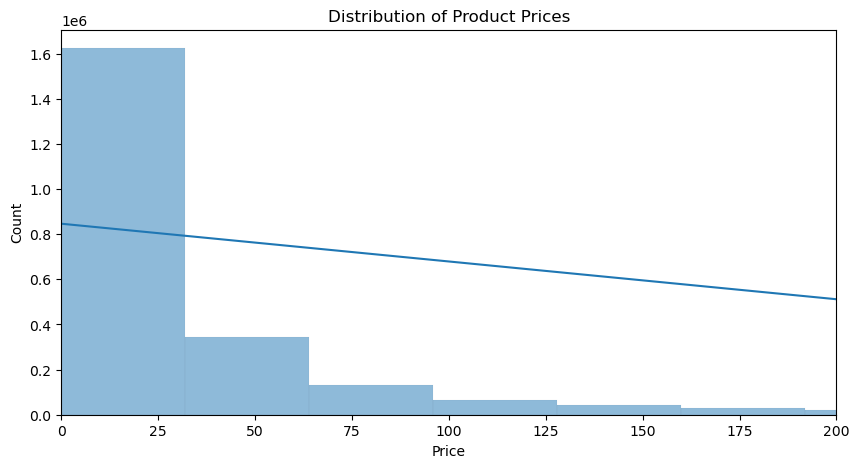

In [23]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x="price", kde=True)
plt.xlim(0, 200)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()

Observation: After limiting the x-axis, the distribution becomes much clearer. Most products are concentrated at lower prices, while the frequency decreases as the price increases. This indicates a right-skewed distribution.

### Outliers

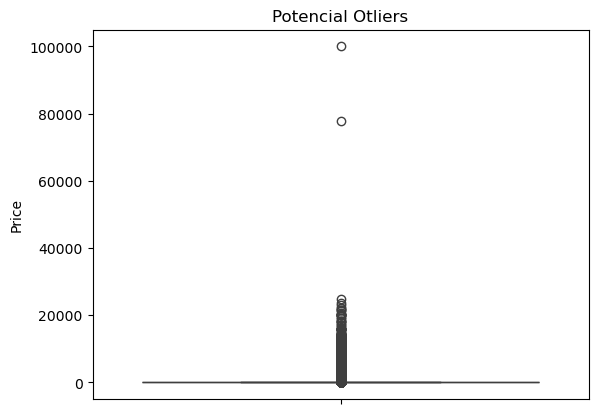

In [24]:
sns.boxplot(data = df, y = "price")

plt.title("Potencial Otliers")
plt.ylabel("Price")

plt.show()

The box plot reveals several high-price outliers, indicating that a small number of products are significantly more expensive than the majority.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [25]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [34]:
df["stars"].mean()

np.float64(2.152836472966066)

In [31]:
df["stars"].median()

0.0

In [32]:
df["stars"].mode()

0    0.0
Name: stars, dtype: float64

In [38]:
df["stars"].var()


4.81743402976196

In [36]:
df["stars"].std()

2.1948653785054697

<Axes: xlabel='stars', ylabel='Count'>

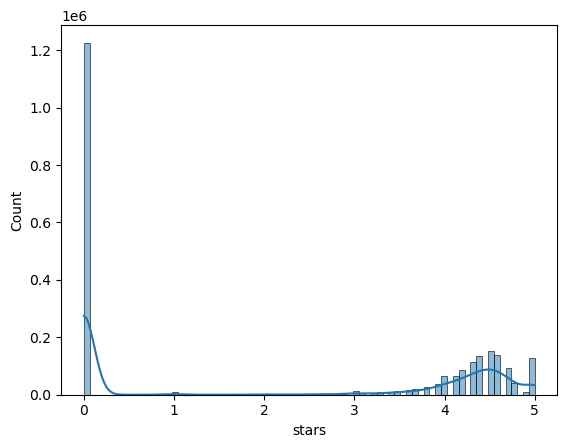

In [37]:
Q1 = df["stars"].quantile(0.25)
Q3 = df["stars"].quantile(0.75)
IQR = Q3 - Q1

# Shape
df["stars"].skew()
df["stars"].kurt()

# Histogram
sns.histplot(data=df, x="stars", kde=True)